# 第四次作业 · 字符级 Transformer 语言模型

给定一段中文前缀，预测下一个字符，并循环采样完成续写。本实验使用课程语料从随机初始化训练 Decoder-only Transformer。Notebook 读取实际训练日志、重绘曲线、加载交付权重重算完整测试集并现场生成文本。完整训练和调参命令见 [README](README.md)。

In [1]:
import json
import math
import sys
from pathlib import Path

import torch
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import Markdown, display

root = Path.cwd().resolve()
if not (root / "config.json").is_file():
    root /= "week04"
sys.path.insert(0, str(root))

from data import BOS, EOS, CORPUS, group_key, read_corpus, vocab_lookup, windows, write_json
from predict import CHECKPOINT, evaluate_checkpoint, generate, load_checkpoint
from train import select_device

results = root / "results"
read = lambda name: json.loads((results / name).read_text(encoding="utf-8"))
stats, trials, final, ngram = map(read, ["data_stats.json", "trials.json", "history.json", "ngram.json"])
device = select_device("auto")
model, checkpoint = load_checkpoint(CHECKPOINT, device)
print(f"训练环境 {final['environment']}")
print(f"当前 Notebook 环境 torch {torch.__version__}, device={device}")
print(f"最优权重来自第 {checkpoint['epoch']} 轮；参数量 {sum(p.numel() for p in model.parameters()):,}")

训练环境 {'python': '3.11.13', 'torch': '2.7.1+cu126', 'cuda': '12.6', 'device': 'NVIDIA GeForce RTX 4060 Laptop GPU', 'precision': 'bf16'}
当前 Notebook 环境 torch 2.7.1+cpu, device=cpu
最优权重来自第 19 轮；参数量 2,557,824


## 1. 语料、划分与监督信号

先做 NFKC 和空白归一化，再精确去重。以忽略标点、大小写和空白后的行作为分组键，固定种子按组划分。只从训练集统计字表。每行添加 BOS/EOS，输入和标签右移一位。长行切窗时共享一个边界字符，每个标签恰好计一次。

In [2]:
split, meta = read_corpus(CORPUS)
assert meta["sha256"] == checkpoint["data_sha256"]
assert meta["split_sha256"] == checkpoint["split_sha256"] == stats["split_sha256"]
keys = {name: {group_key(line) for line in lines} for name, lines in split.items()}
assert not (keys["train"] & keys["val"] or keys["train"] & keys["test"] or keys["val"] & keys["test"])

rows = ["| 划分 | 分组 | 行数 | 字符 | 预测位置（含 EOS） | OOV |",
        "|---|---:|---:|---:|---:|---:|"]
for name, s in stats["splits"].items():
    rows.append(f"| {name} | {stats['groups'][name]:,} | {s['lines']:,} | {s['characters']:,} "
                f"| {s['targets']:,} | {s['oov_rate']:.3%} |")
display(Markdown("\n".join(rows)))
print(f"原始 {stats['raw_lines']:,} 行，移除重复 {stats['duplicate_lines']:,} 行。")
vocab = checkpoint["vocab"]
seq = next(windows(["今天天气"], vocab_lookup(vocab)))
assert seq[0] == BOS and seq[-1] == EOS
print("输入", [vocab[i] for i in seq[:-1]])
print("标签", [vocab[i] for i in seq[1:]])

| 划分 | 分组 | 行数 | 字符 | 预测位置（含 EOS） | OOV |
|---|---:|---:|---:|---:|---:|
| train | 206,809 | 220,983 | 3,482,170 | 3,703,153 | 0.072% |
| val | 11,489 | 12,265 | 196,006 | 208,271 | 0.084% |
| test | 11,489 | 12,304 | 194,356 | 206,660 | 0.094% |

原始 395,286 行，移除重复 149,734 行。
输入 ['<bos>', '今', '天', '天', '气']
标签 ['今', '天', '天', '气', '<eos>']


## 2. 因果注意力

字符与位置嵌入相加，随后通过 Pre-LN 多头自注意力、GELU 前馈层和残差连接。每个位置只允许关注自身及左侧。用训练好的模型验证两个序列在共享前缀上的输出是否一致。

In [3]:
lookup = vocab_lookup(vocab)
seq_a = torch.tensor([[BOS, *[lookup[c] for c in "我喜欢苹果"]]], device=device)
seq_b = torch.tensor([[BOS, *[lookup[c] for c in "我喜欢运动"]]], device=device)
with torch.inference_mode():
    a = model(seq_a)[:, :4]
    b = model(seq_b)[:, :4]
torch.testing.assert_close(a, b, atol=1e-5, rtol=1e-5)
print(f"替换未来字符后的共享前缀 logits 最大绝对差 {float((a - b).abs().max()):.2e}")

替换未来字符后的共享前缀 logits 最大绝对差 0.00e+00


## 3. 学习率搜索与训练曲线

各候选使用同样的模型、种子、批大小和三轮预算，按最佳验证 NLL 排序。用选中的峰值学习率从头进行完整训练，warmup 后以余弦曲线下降。训练 PPL 是训练模式下各批次随参数更新得到的在线值，验证 PPL 在每轮结束后用固定权重和 eval 模式测量。

In [4]:
table = ["| 峰值学习率 | 最优轮次 | 验证 PPL | 验证 Top-1 |",
         "|---:|---:|---:|---:|"]
for trial in trials:
    row = trial["history"][trial["best_epoch"] - 1]
    table.append(f"| {trial['config']['lr']:g} | {row['epoch']} | {row['val']['ppl']:.2f} "
                 f"| {row['val']['top1']:.2%} |")
display(Markdown("\n".join(table)))
print(f"完整训练使用峰值学习率 {final['config']['lr']:g}，耗时 "
      f"{sum(row['seconds'] for row in final['history']):.1f} s")

| 峰值学习率 | 最优轮次 | 验证 PPL | 验证 Top-1 |
|---:|---:|---:|---:|
| 0.0008 | 3 | 39.94 | 35.38% |
| 0.0012 | 3 | 38.16 | 35.93% |
| 0.0016 | 3 | 37.13 | 36.24% |

完整训练使用峰值学习率 0.0016，耗时 265.2 s


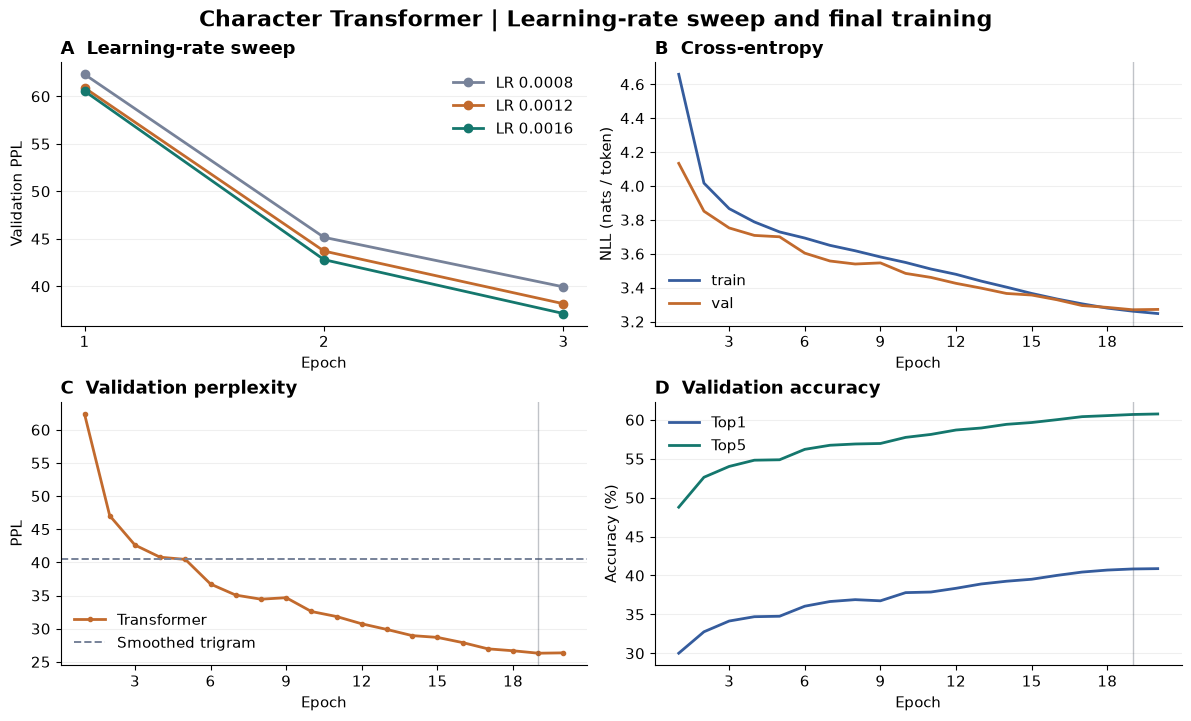

In [5]:
history = final["history"]
epochs = [row["epoch"] for row in history]
best = final["best_epoch"]

with plt.rc_context({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"}):
    fig, axs = plt.subplots(2, 2, figsize=(11.8, 7.1), layout="constrained")
    fig.suptitle("Character Transformer | Learning-rate sweep and final training",
                 fontweight="bold", fontsize=16)
    sweep, loss, ppl, acc = axs.flat
    for trial, color in zip(trials, ("#778299", "#C26A2D", "#14776D")):
        rows = trial["history"]
        sweep.plot([row["epoch"] for row in rows], [row["val"]["ppl"] for row in rows],
                   "o-", color=color, linewidth=2, label=f"LR {trial['config']['lr']:g}")
    sweep.set(title="A  Learning-rate sweep", ylabel="Validation PPL", xticks=[1, 2, 3])
    sweep.legend(frameon=False)

    for name, color in (("train", "#355C9D"), ("val", "#C26A2D")):
        loss.plot(epochs, [row[name]["nll"] for row in history], linewidth=2, color=color, label=name)
    loss.set(title="B  Cross-entropy", ylabel="NLL (nats / token)")
    loss.legend(frameon=False)

    ppl.plot(epochs, [row["val"]["ppl"] for row in history], "o-", markersize=3,
             color="#C26A2D", linewidth=2, label="Transformer")
    ppl.axhline(ngram["3-gram"]["val"]["ppl"], linestyle="--", linewidth=1.4,
                color="#778299", label="Smoothed trigram")
    ppl.set(title="C  Validation perplexity", ylabel="PPL")
    ppl.legend(frameon=False)

    for name, color in (("top1", "#355C9D"), ("top5", "#14776D")):
        acc.plot(epochs, [100 * row["val"][name] for row in history],
                 linewidth=2, color=color, label=name.capitalize())
    acc.set(title="D  Validation accuracy", ylabel="Accuracy (%)")
    acc.legend(frameon=False)
    for ax in axs.flat:
        ax.grid(axis="y", alpha=0.2)
        ax.set_xlabel("Epoch")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=8))
    for ax in (loss, ppl, acc):
        ax.axvline(best, color="#4B5563", linewidth=1, alpha=0.35)
    fig.savefig(results / "learning_curves.png", dpi=160, facecolor="white")
    plt.show()

## 4. 独立测试集

对全部测试目标重算 NLL、PPL 和 Top-k 命中率。三种 N-gram 使用相同的字符表、窗口和标签，平滑强度在验证集选择。

In [6]:
test = evaluate_checkpoint(model, checkpoint, CORPUS, "test", 128, device)
recorded = read("test.json")
assert test["tokens"] == recorded["tokens"] == stats["splits"]["test"]["targets"]
assert math.isclose(test["ppl"], recorded["ppl"], rel_tol=0.001)

rows = ["| 模型 | 验证 PPL | 测试 PPL | 测试目标数 |",
        "|---|---:|---:|---:|"]
for name, s in ngram.items():
    rows.append(f"| {name} | {s['val']['ppl']:.2f} | {s['test']['ppl']:.2f} | {s['test']['tokens']:,} |")
rows.append(f"| Transformer | {checkpoint['validation']['ppl']:.2f} "
            f"| {test['ppl']:.2f} | {test['tokens']:,} |")
display(Markdown("\n".join(rows)))
print(f"测试 NLL {test['nll']:.4f} nat/token，Top-1 {test['top1']:.2%}，Top-5 {test['top5']:.2%}")
drop = 1 - test["ppl"] / ngram["3-gram"]["test"]["ppl"]
print(f"相对三元模型，测试 PPL 下降 {drop:.2%}。")

| 模型 | 验证 PPL | 测试 PPL | 测试目标数 |
|---|---:|---:|---:|
| 1-gram | 594.59 | 588.71 | 206,660 |
| 2-gram | 72.59 | 73.09 | 206,660 |
| 3-gram | 40.53 | 41.39 | 206,660 |
| Transformer | 26.30 | 26.81 | 206,660 |

测试 NLL 3.2888 nat/token，Top-1 40.51%，Top-5 60.47%
相对三元模型，测试 PPL 下降 35.22%。


## 5. 固定前缀生成

比较 greedy 和温度 0.85、Top-k 40、Top-p 0.9 的采样。模型预测 EOS 时结束。分隔符 `│` 左侧为前缀，右侧为新增文本。

In [7]:
cases = [
    ("如何学习", 0.0, 42),
    ("如何学习", 0.85, 42),
    ("如何学习", 0.85, 43),
    ("我的手机", 0.85, 42),
    ("今天天气", 0.85, 42),
    ("在轨道空间站里", 0.85, 42),
]
examples = []
train_lines = set(split["train"])
for prompt, temperature, seed in cases:
    example = generate(model, vocab, prompt, max_new=48, temperature=temperature, seed=seed)
    in_train = example["text"] in train_lines
    examples.append({"temperature": temperature, "seed": seed, "exact_match_in_train": in_train,
                     **example})
    print(f"{temperature:g} / seed {seed}  {example['prompt']}│{example['continuation']}  "
          f"(EOS={example['stopped_by_eos']}, 训练集整句匹配={in_train})")
write_json(results / "generation_examples.json", {
    "device": str(device), "torch": str(torch.__version__), "top_k": 40,
    "top_p": 0.9, "max_new": 48, "examples": examples,
})

0 / seed 42  如何学习│英语  (EOS=True, 训练集整句匹配=True)
0.85 / seed 42  如何学习│英语单词  (EOS=True, 训练集整句匹配=False)
0.85 / seed 43  如何学习│拼音  (EOS=True, 训练集整句匹配=False)
0.85 / seed 42  我的手机│怎么注册淘宝账户  (EOS=True, 训练集整句匹配=False)
0.85 / seed 42  今天天气│怎样  (EOS=True, 训练集整句匹配=False)
0.85 / seed 42  在轨道空间站里│怎么刷金币?  (EOS=True, 训练集整句匹配=False)


## 6. 结果解释

这套指标衡量同一语料分布内的字符预测。测试集包含 EOS，Top-k 同时反映下一个字符和句末的预测。模型从训练语料继承了搜索问句和短句的风格。较低的 PPL 衡量模型给真实后续分配的概率，长文本连贯性和事实正确性需要另外评估。

分组划分阻止了已定义的格式变体跨集合，但仍可能有语义改写和共享模板。字符级上下文限制在 64 步，长行跨窗口的历史会丢失。学习率网格只比较了同一个随机种子下的三个点，因此结论限于这套数据、模型和训练预算。